# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Vasavijoshi/flyrank-ml-internship/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

*The research question and the decision it supports.*

In [2]:
from IPython.display import display, Markdown

display(Markdown("""
## Research question

Which content pages should be reviewed first for refresh, expansion,
protection, pruning, or monitoring?

### Decision supported

This project helps a content team prioritize pages for human review
using measurable search visibility, engagement, freshness, and content
characteristics.

The unit of analysis is one content page. The intended output is a
ranked review queue containing a model-based decline probability,
a reason code, and a suggested review action.

### Why machine learning?

A fixed rule can identify obvious cases, such as older pages with high
search visibility. A Random Forest can combine several signals and
capture nonlinear relationships that a simple rule may miss.

The goal is not to automate editorial decisions. It is to help reviewers
decide which pages to investigate first.

### Target and research framing

The target proxy is:

`is_declining_label = (trend_direction == "down")`

This proxy is derived from the available dataset and is not a guaranteed
future outcome. The model is evaluated as a ranking aid using Precision@K.
Its scores do not prove that a page will decline or that refreshing a
page will cause better search performance.
"""))


## Research question

Which content pages should be reviewed first for refresh, expansion,
protection, pruning, or monitoring?

### Decision supported

This project helps a content team prioritize pages for human review
using measurable search visibility, engagement, freshness, and content
characteristics.

The unit of analysis is one content page. The intended output is a
ranked review queue containing a model-based decline probability,
a reason code, and a suggested review action.

### Why machine learning?

A fixed rule can identify obvious cases, such as older pages with high
search visibility. A Random Forest can combine several signals and
capture nonlinear relationships that a simple rule may miss.

The goal is not to automate editorial decisions. It is to help reviewers
decide which pages to investigate first.

### Target and research framing

The target proxy is:

`is_declining_label = (trend_direction == "down")`

This proxy is derived from the available dataset and is not a guaranteed
future outcome. The model is evaluated as a ranking aid using Precision@K.
Its scores do not prove that a page will decline or that refreshing a
page will cause better search performance.


## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

In [3]:
from IPython.display import display, Markdown

display(Markdown("""
## Dataset and release

The FlyRank ML Internship provides a full search-intelligence warehouse
of approximately 79 million rows and a smaller anonymized starter dataset.

The reported modeling and validation results in this study use the
**30,000-page anonymized starter dataset**, which contains 44 columns.
The larger warehouse was used in the earlier data-contract stage to
verify the intended daily search-performance grain and February 2026
feature window. The Random Forest was not trained on the full warehouse.

### Data-contract context

The earlier data-contract work examined the warehouse table
`fact_content_daily_performance` and used `dim_content` when content
metadata was required. The feature window was February 1–28, 2026,
with a decision cutoff at the end of February.

The warehouse checks covered 7,351,108 daily-grain rows. GSC data was
available for 2,621,783 of those rows. The later modeling results
reported in this paper come from the separate 30,000-page starter dataset.

### Modeling features

The final Random Forest used these 12 features:

- `days_since_last_update`
- `impressions_90d`
- `clicks_90d`
- `sessions_90d`
- `ctr`
- `avg_position`
- `engagement_rate`
- `scroll_rate`
- `content_age_days`
- `word_count`
- `search_volume`
- `cpc`

### Target and exclusions

The target proxy was defined as:

`is_declining_label = (trend_direction == "down")`

The fields `trend_direction` and `trend_pct` were excluded because they
are outcome-derived fields. The target `is_declining_label` was not used
as an input feature. The pseudonymous identifiers `content_id` and
`client_id` were also excluded from model inputs; `client_id` was used
only to keep each client's pages together during grouped validation.

Future-window information and other outcome-derived fields were excluded
to reduce target leakage.

### Data safety

The paper presents aggregate metrics and methodology. It does not
publish client names, private search queries, or identifying client URLs.
The ranked output is intended for review, not as a public list of
individual client pages.
"""))


## Dataset and release

The FlyRank ML Internship provides a full search-intelligence warehouse
of approximately 79 million rows and a smaller anonymized starter dataset.

The reported modeling and validation results in this study use the
**30,000-page anonymized starter dataset**, which contains 44 columns.
The larger warehouse was used in the earlier data-contract stage to
verify the intended daily search-performance grain and February 2026
feature window. The Random Forest was not trained on the full warehouse.

### Data-contract context

The earlier data-contract work examined the warehouse table
`fact_content_daily_performance` and used `dim_content` when content
metadata was required. The feature window was February 1–28, 2026,
with a decision cutoff at the end of February.

The warehouse checks covered 7,351,108 daily-grain rows. GSC data was
available for 2,621,783 of those rows. The later modeling results
reported in this paper come from the separate 30,000-page starter dataset.

### Modeling features

The final Random Forest used these 12 features:

- `days_since_last_update`
- `impressions_90d`
- `clicks_90d`
- `sessions_90d`
- `ctr`
- `avg_position`
- `engagement_rate`
- `scroll_rate`
- `content_age_days`
- `word_count`
- `search_volume`
- `cpc`

### Target and exclusions

The target proxy was defined as:

`is_declining_label = (trend_direction == "down")`

The fields `trend_direction` and `trend_pct` were excluded because they
are outcome-derived fields. The target `is_declining_label` was not used
as an input feature. The pseudonymous identifiers `content_id` and
`client_id` were also excluded from model inputs; `client_id` was used
only to keep each client's pages together during grouped validation.

Future-window information and other outcome-derived fields were excluded
to reduce target leakage.

### Data safety

The paper presents aggregate metrics and methodology. It does not
publish client names, private search queries, or identifying client URLs.
The ranked output is intended for review, not as a public list of
individual client pages.


## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

In [4]:
from IPython.display import display, Markdown

display(Markdown("""
## Methodology

### Research assumptions

The analysis treats the dataset's declining label as a proxy for ranking
content pages for review. It assumes that historical search, engagement,
freshness, and content characteristics may help distinguish pages with
different observed trend labels. It does not assume that these signals
prove why a page declined or that refreshing it will cause improvement.

### Baseline

The transparent Week-4 baseline combined page freshness and search visibility.

Staleness points:
- 0 points: `days_since_last_update <= 90`
- 1 point: 91–180 days
- 2 points: more than 180 days

Visibility points:
- 0 points: fewer than 250 impressions
- 1 point: 250–499 impressions
- 2 points: at least 500 impressions

The two scores were added to create a score from 0 to 4. Pages scoring
at least 3 received the `Refresh` action; all others received `Monitor`.

### Random Forest model

The model was a Random Forest classifier with 300 trees,
`random_state=42`, `min_samples_leaf=5`, and median imputation.

It used 12 features: `days_since_last_update`, `impressions_90d`,
`clicks_90d`, `sessions_90d`, `ctr`, `avg_position`, `engagement_rate`,
`scroll_rate`, `content_age_days`, `word_count`, `search_volume`, and `cpc`.

The target proxy was:

`is_declining_label = (trend_direction == "down")`

The target and its derived fields were not included among the input features.

### Validation design

The primary evaluation used a client-grouped holdout. All pages belonging
to a client were kept in the same partition to assess performance on
clients not represented in training.

- Training: 23,837 rows from 25 clients
- Test: 6,163 rows from 7 clients
- Client overlap: 0
- Declining/positive rate in the test set: 51.1%

The main metric was Precision@K at K=10, 50, and 100 because the intended
use is to prioritize a limited number of pages for human review.

### Leakage checks

The final feature audit excluded `trend_direction`, `trend_pct`,
`is_declining_label`, `content_id`, and `client_id` from model inputs.
The audit found no forbidden features, no target included as a feature,
no missing final features, and no outcome-like feature names.

An earlier leakage experiment deliberately introduced a future
outcome-derived feature and produced an artificially perfect score of
1.0000. This demonstrated why future or label-derived information must
not be used as a model input.

### Reproducibility

The Random Forest and baseline were compared on the same grouped-client
holdout using the same Precision@K metric. The random-row-split results
are reported separately as a validation-sensitivity comparison, not as
the primary performance estimate.
"""))


## Methodology

### Research assumptions

The analysis treats the dataset's declining label as a proxy for ranking
content pages for review. It assumes that historical search, engagement,
freshness, and content characteristics may help distinguish pages with
different observed trend labels. It does not assume that these signals
prove why a page declined or that refreshing it will cause improvement.

### Baseline

The transparent Week-4 baseline combined page freshness and search visibility.

Staleness points:
- 0 points: `days_since_last_update <= 90`
- 1 point: 91–180 days
- 2 points: more than 180 days

Visibility points:
- 0 points: fewer than 250 impressions
- 1 point: 250–499 impressions
- 2 points: at least 500 impressions

The two scores were added to create a score from 0 to 4. Pages scoring
at least 3 received the `Refresh` action; all others received `Monitor`.

### Random Forest model

The model was a Random Forest classifier with 300 trees,
`random_state=42`, `min_samples_leaf=5`, and median imputation.

It used 12 features: `days_since_last_update`, `impressions_90d`,
`clicks_90d`, `sessions_90d`, `ctr`, `avg_position`, `engagement_rate`,
`scroll_rate`, `content_age_days`, `word_count`, `search_volume`, and `cpc`.

The target proxy was:

`is_declining_label = (trend_direction == "down")`

The target and its derived fields were not included among the input features.

### Validation design

The primary evaluation used a client-grouped holdout. All pages belonging
to a client were kept in the same partition to assess performance on
clients not represented in training.

- Training: 23,837 rows from 25 clients
- Test: 6,163 rows from 7 clients
- Client overlap: 0
- Declining/positive rate in the test set: 51.1%

The main metric was Precision@K at K=10, 50, and 100 because the intended
use is to prioritize a limited number of pages for human review.

### Leakage checks

The final feature audit excluded `trend_direction`, `trend_pct`,
`is_declining_label`, `content_id`, and `client_id` from model inputs.
The audit found no forbidden features, no target included as a feature,
no missing final features, and no outcome-like feature names.

An earlier leakage experiment deliberately introduced a future
outcome-derived feature and produced an artificially perfect score of
1.0000. This demonstrated why future or label-derived information must
not be used as a model input.

### Reproducibility

The Random Forest and baseline were compared on the same grouped-client
holdout using the same Precision@K metric. The random-row-split results
are reported separately as a validation-sensitivity comparison, not as
the primary performance estimate.


## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*


## Model versus baseline

The Random Forest was compared with the Week-4 rule-based baseline on
the same client-grouped holdout using Precision@K.

The grouped-client test set had a declining/positive rate of **51.1%**.
This base rate provides context for interpreting the ranking metrics.


,K,Week-4 baseline,Random Forest — grouped client split,Random Forest — random row split (sensitivity only)
0,10,0.3,0.50,1.00
1,50,0.3,0.64,0.96
2,100,0.3,0.61,0.94


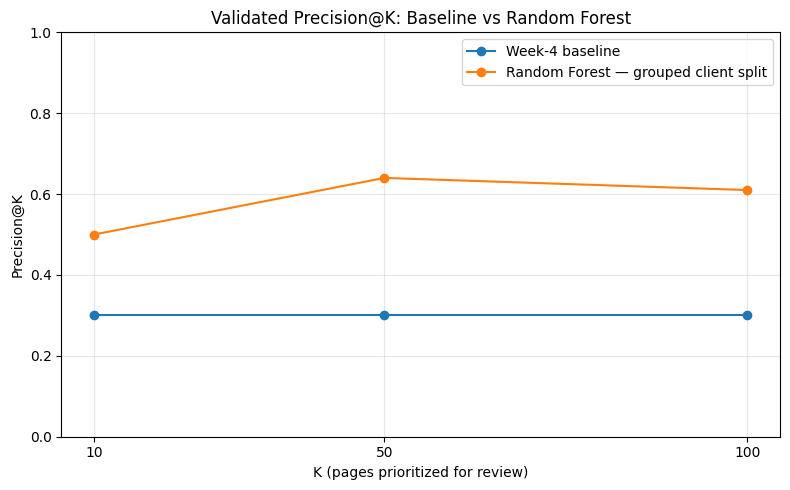

Figure saved: /content/flyrank-ml-internship/work/figures/precision_at_k_baseline_vs_random_forest.png
Metrics saved: /content/flyrank-ml-internship/work/outputs/ml09_validation_metrics.json



### Validation sensitivity

The random row split measured Precision@10, @50, and @100 of 1.00, 0.96,
and 0.94, respectively. However, it allowed pages from the same clients
to appear in both training and test sets. It is therefore shown only as
a sensitivity reference.

The grouped-client split had zero client overlap and is the primary
evaluation for decision support involving unseen clients.

### Honest interpretation

The Random Forest measured higher Precision@K than the baseline at all
three cutoffs on this holdout. These are observed results on this dataset
and split; they do not establish future performance or causal impact.


In [5]:
from IPython.display import display, Markdown
import matplotlib.pyplot as plt
import pandas as pd
import os

# Create folders for paper artifacts
repo_root = "/content/flyrank-ml-internship"
figures_dir = os.path.join(repo_root, "work", "figures")
outputs_dir = os.path.join(repo_root, "work", "outputs")

os.makedirs(figures_dir, exist_ok=True)
os.makedirs(outputs_dir, exist_ok=True)

# Verified evaluation results from ML-08 and ML-09
ks = [10, 50, 100]
baseline_precision = [0.30, 0.30, 0.30]
rf_grouped_precision = [0.50, 0.64, 0.61]
rf_random_precision = [1.00, 0.96, 0.94]

results_table = pd.DataFrame({
    "K": ks,
    "Week-4 baseline": baseline_precision,
    "Random Forest — grouped client split": rf_grouped_precision,
    "Random Forest — random row split (sensitivity only)": rf_random_precision
})

display(Markdown("""
## Model versus baseline

The Random Forest was compared with the Week-4 rule-based baseline on
the same client-grouped holdout using Precision@K.

The grouped-client test set had a declining/positive rate of **51.1%**.
This base rate provides context for interpreting the ranking metrics.
"""))

display(results_table)

# Plot the primary comparison only
plt.figure(figsize=(8, 5))
plt.plot(ks, baseline_precision, marker="o", label="Week-4 baseline")
plt.plot(
    ks,
    rf_grouped_precision,
    marker="o",
    label="Random Forest — grouped client split"
)
plt.xlabel("K (pages prioritized for review)")
plt.ylabel("Precision@K")
plt.title("Validated Precision@K: Baseline vs Random Forest")
plt.xticks(ks)
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

figure_path = os.path.join(
    figures_dir, "precision_at_k_baseline_vs_random_forest.png"
)
plt.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

# Save metrics for reproducibility
metrics = {
    "evaluation_split": "grouped client holdout",
    "training_rows": 23837,
    "training_clients": 25,
    "test_rows": 6163,
    "test_clients": 7,
    "client_overlap": 0,
    "test_positive_rate": 0.511,
    "k_values": ks,
    "baseline_precision_at_k": baseline_precision,
    "random_forest_grouped_precision_at_k": rf_grouped_precision,
    "random_forest_random_row_split_precision_at_k_sensitivity_only": rf_random_precision
}

import json

metrics_path = os.path.join(outputs_dir, "ml09_validation_metrics.json")
with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

print("Figure saved:", figure_path)
print("Metrics saved:", metrics_path)

display(Markdown("""
### Validation sensitivity

The random row split measured Precision@10, @50, and @100 of 1.00, 0.96,
and 0.94, respectively. However, it allowed pages from the same clients
to appear in both training and test sets. It is therefore shown only as
a sensitivity reference.

The grouped-client split had zero client overlap and is the primary
evaluation for decision support involving unseen clients.

### Honest interpretation

The Random Forest measured higher Precision@K than the baseline at all
three cutoffs on this holdout. These are observed results on this dataset
and split; they do not establish future performance or causal impact.
"""))

## 5. Limitations

*What this work cannot claim.*

In [6]:
from IPython.display import display, Markdown

display(Markdown("""
## Limitations and honest framing

### 1. Dataset scope

The reported modeling and validation results use the 30,000-page
anonymized starter dataset, not the full approximately 79-million-row
warehouse. The larger warehouse was used earlier for data-contract
verification. Results should not be presented as if the model was
trained or evaluated on all 79 million rows.

### 2. Proxy target

The target is a dataset-derived proxy defined from `trend_direction`.
It is not a guaranteed future outcome. A high model score does not
guarantee that a page will decline.

### 3. Generalization

The primary evaluation uses one client-grouped holdout containing
25 training clients and 7 test clients, with zero client overlap.
This is more appropriate for unseen-client evaluation than a random
row split, but it does not establish performance across every client,
future time period, search environment, or content type.

### 4. Metric limitations

Precision@K measures the proportion of declining-label pages among
the top-ranked pages at selected cutoffs. It does not establish the
business value of a recommended refresh, and it does not by itself
show that the model will improve editorial outcomes.

The test-set declining-label rate was 51.1%. The measured Precision@K
results should be interpreted alongside this base rate and the
validation design.

### 5. No causal evidence

This evaluation did not use a randomized refresh intervention.
It therefore cannot establish that refreshing a page causes improved
search performance.

### 6. Human review remains necessary

The queue is a decision-support artifact. Reviewers should consider
search intent, factual accuracy, business importance, seasonality,
strategic content value, and recent page changes before acting.

The model should not autonomously publish, rewrite, delete, redirect,
or otherwise modify content.
"""))


## Limitations and honest framing

### 1. Dataset scope

The reported modeling and validation results use the 30,000-page
anonymized starter dataset, not the full approximately 79-million-row
warehouse. The larger warehouse was used earlier for data-contract
verification. Results should not be presented as if the model was
trained or evaluated on all 79 million rows.

### 2. Proxy target

The target is a dataset-derived proxy defined from `trend_direction`.
It is not a guaranteed future outcome. A high model score does not
guarantee that a page will decline.

### 3. Generalization

The primary evaluation uses one client-grouped holdout containing
25 training clients and 7 test clients, with zero client overlap.
This is more appropriate for unseen-client evaluation than a random
row split, but it does not establish performance across every client,
future time period, search environment, or content type.

### 4. Metric limitations

Precision@K measures the proportion of declining-label pages among
the top-ranked pages at selected cutoffs. It does not establish the
business value of a recommended refresh, and it does not by itself
show that the model will improve editorial outcomes.

The test-set declining-label rate was 51.1%. The measured Precision@K
results should be interpreted alongside this base rate and the
validation design.

### 5. No causal evidence

This evaluation did not use a randomized refresh intervention.
It therefore cannot establish that refreshing a page causes improved
search performance.

### 6. Human review remains necessary

The queue is a decision-support artifact. Reviewers should consider
search intent, factual accuracy, business importance, seasonality,
strategic content value, and recent page changes before acting.

The model should not autonomously publish, rewrite, delete, redirect,
or otherwise modify content.


## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

In [7]:
from IPython.display import display, Markdown

display(Markdown("""
## Ranked recommendations: Content action playbook

The ranked queue is designed to help content teams decide which pages
to investigate first. It is not an automatic content-change system.

### Priority levels

| Priority | Decline probability | Recommended next step |
|---|---:|---|
| Priority review | >= 0.70 | Investigate first; verify the signals and page context |
| Review | >= 0.50 and < 0.70 | Investigate after the priority queue |
| Monitor | < 0.50 | Continue monitoring unless other evidence appears |

These thresholds are operational prioritization choices, not calibrated
guarantees of future decline.

### Reason codes and suggested actions

| Reason code | Trigger | Suggested action |
|---|---|---|
| `STALE_HIGH_VISIBILITY` | More than 180 days since update and at least 500 impressions | Priority refresh review |
| `STALE_PAGE` | More than 180 days since update | Investigate whether the page needs refreshing |
| `HIGH_VISIBILITY_REVIEW` | At least 500 impressions and elevated model ranking | Review search performance and intent alignment |
| `AGING_PAGE` | More than 90 days since update | Monitor or investigate freshness |
| `MONITOR` | No higher-priority rule applies | Continue monitoring |

### Human review workflow

**Rank → investigate → validate context → decide → act → monitor**

Before taking action, the reviewer should check:

- Search intent and whether the page meets the user's needs
- Factual accuracy and whether information is current
- Business importance and strategic content value
- Seasonality and recent content changes
- Search-ranking context and whether the available signals remain representative
- Whether the page is intentionally protected or should remain unchanged

### What must not be automated

The system must not autonomously publish or rewrite content, delete
pages, change redirects or canonicals, make factual or editorial
decisions, or treat a model score as proof that refreshing will improve
search performance.

### Cost and value

The intended value is to help reviewers spend limited time on a ranked
set of pages rather than inspect every page equally. The main cost is
reviewer time spent investigating pages that do not need action, while
a lower-ranked page that needs attention may be missed. The queue should
therefore be monitored and reviewed by people who understand the
content and business context.
"""))


## Ranked recommendations: Content action playbook

The ranked queue is designed to help content teams decide which pages
to investigate first. It is not an automatic content-change system.

### Priority levels

| Priority | Decline probability | Recommended next step |
|---|---:|---|
| Priority review | >= 0.70 | Investigate first; verify the signals and page context |
| Review | >= 0.50 and < 0.70 | Investigate after the priority queue |
| Monitor | < 0.50 | Continue monitoring unless other evidence appears |

These thresholds are operational prioritization choices, not calibrated
guarantees of future decline.

### Reason codes and suggested actions

| Reason code | Trigger | Suggested action |
|---|---|---|
| `STALE_HIGH_VISIBILITY` | More than 180 days since update and at least 500 impressions | Priority refresh review |
| `STALE_PAGE` | More than 180 days since update | Investigate whether the page needs refreshing |
| `HIGH_VISIBILITY_REVIEW` | At least 500 impressions and elevated model ranking | Review search performance and intent alignment |
| `AGING_PAGE` | More than 90 days since update | Monitor or investigate freshness |
| `MONITOR` | No higher-priority rule applies | Continue monitoring |

### Human review workflow

**Rank → investigate → validate context → decide → act → monitor**

Before taking action, the reviewer should check:

- Search intent and whether the page meets the user's needs
- Factual accuracy and whether information is current
- Business importance and strategic content value
- Seasonality and recent content changes
- Search-ranking context and whether the available signals remain representative
- Whether the page is intentionally protected or should remain unchanged

### What must not be automated

The system must not autonomously publish or rewrite content, delete
pages, change redirects or canonicals, make factual or editorial
decisions, or treat a model score as proof that refreshing will improve
search performance.

### Cost and value

The intended value is to help reviewers spend limited time on a ranked
set of pages rather than inspect every page equally. The main cost is
reviewer time spent investigating pages that do not need action, while
a lower-ranked page that needs attention may be missed. The queue should
therefore be monitored and reviewed by people who understand the
content and business context.


## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

## Paper-ready results table

,K,Baseline,Random Forest — grouped client split,Random Forest — random row split (sensitivity only)
0,10,0.3,0.50,1.00
1,50,0.3,0.64,0.96
2,100,0.3,0.61,0.94


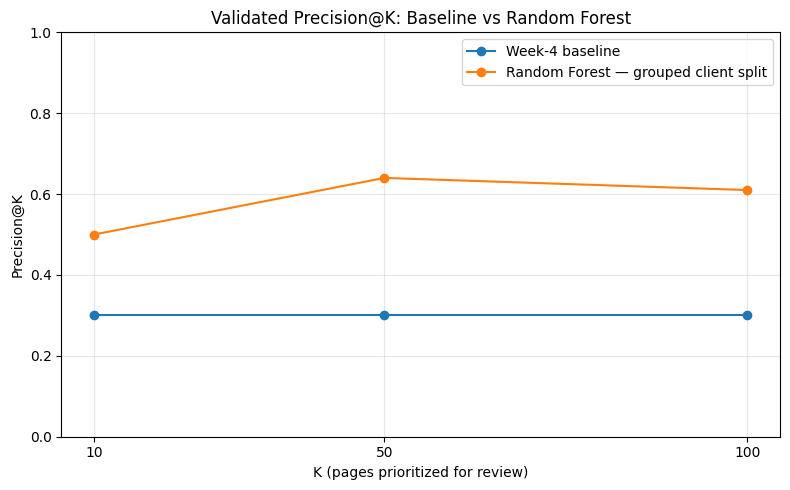


Artifacts generated:
/content/flyrank-ml-internship/work/figures/precision_at_k_baseline_vs_random_forest.png
/content/flyrank-ml-internship/work/outputs/ml09_validation_metrics.json



### Interpretation

The grouped-client evaluation is the primary result. The random-row-split
metrics are included only to demonstrate how validation design changes
measured performance. These results are directional evidence for
human-review prioritization, not a causal claim or guarantee of future
performance.


In [8]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

repo_root = "/content/flyrank-ml-internship"
figures_dir = os.path.join(repo_root, "work", "figures")
outputs_dir = os.path.join(repo_root, "work", "outputs")

os.makedirs(figures_dir, exist_ok=True)
os.makedirs(outputs_dir, exist_ok=True)

# Results verified in the completed ML-08 and ML-09 notebooks
ks = [10, 50, 100]
baseline = [0.30, 0.30, 0.30]
rf_grouped = [0.50, 0.64, 0.61]
rf_random = [1.00, 0.96, 0.94]

results = pd.DataFrame({
    "K": ks,
    "Baseline": baseline,
    "Random Forest — grouped client split": rf_grouped,
    "Random Forest — random row split (sensitivity only)": rf_random
})

display(Markdown("## Paper-ready results table"))
display(results)

# Generate the primary comparison figure
plt.figure(figsize=(8, 5))
plt.plot(ks, baseline, marker="o", label="Week-4 baseline")
plt.plot(ks, rf_grouped, marker="o",
         label="Random Forest — grouped client split")
plt.xlabel("K (pages prioritized for review)")
plt.ylabel("Precision@K")
plt.title("Validated Precision@K: Baseline vs Random Forest")
plt.xticks(ks)
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

figure_path = os.path.join(
    figures_dir, "precision_at_k_baseline_vs_random_forest.png"
)
plt.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

# Save the validation metrics record
metrics = {
    "primary_split": "grouped client holdout",
    "training_rows": 23837,
    "training_clients": 25,
    "test_rows": 6163,
    "test_clients": 7,
    "client_overlap": 0,
    "test_positive_rate": 0.511,
    "k_values": ks,
    "baseline_precision_at_k": baseline,
    "random_forest_grouped_precision_at_k": rf_grouped,
    "random_forest_random_row_split_sensitivity_only": rf_random
}

metrics_path = os.path.join(outputs_dir, "ml09_validation_metrics.json")
with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

print("\nArtifacts generated:")
print(figure_path)
print(metrics_path)

display(Markdown("""
### Interpretation

The grouped-client evaluation is the primary result. The random-row-split
metrics are included only to demonstrate how validation design changes
measured performance. These results are directional evidence for
human-review prioritization, not a causal claim or guarantee of future
performance.
"""))

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
